## UTS Graf Sains Data
Lofian Rafi Qurrotul Ain
23031554221

In [1]:
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "utsgrafsada")

In [4]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
        )

In [5]:
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH, ) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


**Pertanyaan Pendahuluan**
1. Apa nama database yang digunakan pada tutorial ini?

Jawaban : neo4j

2. Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses databse lain dalam 1 instance!

Jawaban : 
- Klausul Cypher: Klausul resmi Cypher yang diletakkan di awal query untuk mengarahkan eksekusi query ke database tertentu dalam 1 instance (contoh: USE system SHOW DATABASES; atau USE neo4j MATCH (n) RETURN n;).
- Perintah Client/Browser :use <database_name>: Perintah interaktif pada Neo4j Browser atau Cypher Shell CLI untuk berpindah konteks database aktif (contoh: :use system).
- Parameter Database pada Driver SDK: Penentuan nama database saat membuka sesi atau eksekusi kueri melalui driver program (contoh pada Python: driver.session(database="system") atau driver.execute_query(..., database_="neo4j")).
- Sintaks DDL: Digunakan untuk mengelola multi-database dalam instance, seperti: SHOW DATABASES, CREATE DATABASE <nama>, STOP DATABASE <nama>, dan DROP DATABASE <nama>.

3. Apa jenis graf pertemanan yang telah dibuat di sini?

Jawaban : 
- Graf Berarah (Directed Graph)
- Graf Tidak Berbobot (Unweighted Graph)

Mekanisme Neo4j

In [2]:
from neo4j import GraphDatabase

driver = GraphDatabase.driver(URI, auth=AUTH)
session = driver.session(database="system")

In [3]:
def create_constraints(session):
    # Menggunakan visitorId dan itemId (I kapital) agar indeks terpakai!
    session.run(
        "CREATE CONSTRAINT IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE"
    )
    session.run(
        "CREATE CONSTRAINT IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE"
    )
    print("Constraints (visitorId & itemId) berhasil dibuat/diverifikasi.")


def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

In [4]:
import argparse

def parse_arguments():
    parser = argparse.ArgumentParser(
        description="Impor dataset RetailRocket (events.csv) ke database Neo4J."
    )
    parser.add_argument(
        "-u", "--user", default="neo4j", help="Username Neo4j (default: neo4j)"
    )
    parser.add_argument(
        "-p",
        "--password",
        default="utsgrafsada",
        help="Password Neo4J (default: utsgrafsada)",
    )
    parser.add_argument(
        "-b",
        "--bolt",
        default="neo4j://127.0.0.1:7687",
        help="Neo4J URI / Bolt (default: neo4j://127.0.0.1:7687)",
    )
    parser.add_argument(
        "-s",
        "--source",
        default=r"C:\Users\lovia\Documents\SEMESTER 7\Graf Sains Data\UTS\dataset",  
        help="Direktori/folder sumber data",
    )
    return parser.parse_args(args=[])

File Event

In [5]:
import os
import sys

args = parse_arguments()

csv_file_path = os.path.join(args.source, "events_P1.csv")

if not os.path.exists(csv_file_path):
    print(f"Error: File '{csv_file_path}' tidak ditemukan!")
    sys.exit(1)


In [6]:
from neo4j import GraphDatabase

try:
    driver = GraphDatabase.driver(
        args.bolt, auth=(args.user, args.password)
    )
    driver.verify_connectivity()
except Exception as e:
    print(f" Gagal terhubung ke database: {e}")
    sys.exit(1)


In [13]:
import os
import pandas as pd
from tqdm import tqdm

batch_size = 10000

print(f"Menganalisis dan menghitung baris dari: {csv_file_path} ...")
total_rows = sum(1 for _ in open(csv_file_path)) - 1
total_chunks = (total_rows // batch_size) + 1

print(f"Total baris ditemukan: {total_rows:,} baris")

with driver.session() as session:
    create_constraints(session)

    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

    print("Memulai proses impor data ke Neo4j...")
    for chunk in tqdm(
        chunks, total=total_chunks, desc="Mengimpor Batch Data"
    ):
        chunk["transactionid"] = (
            chunk["transactionid"].fillna("").astype(str)
        )

        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

driver.close()
print("Proses impor berhasil.")

Menganalisis dan menghitung baris dari: C:\Users\lovia\Documents\SEMESTER 7\Graf Sains Data\UTS\dataset\events_P1.csv ...
Total baris ditemukan: 141,200 baris
Constraints (visitorId & itemId) berhasil dibuat/diverifikasi.
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 15/15 [00:37<00:00,  2.52s/it]

Proses impor berhasil.


Melihat Timestamp

In [ ]:
import pandas as pd

df = pd.read_csv("C:/Users/lovia/Documents/SEMESTER 7/Graf Sains Data/UTS/dataset/events.csv")

df['datetime'] = pd.to_datetime(df['timestamp'], unit='ms')

min_ts = df['datetime'].min()
max_ts = df['datetime'].max()

tanggal_awal = pd.to_datetime(min_ts, unit="ms")
tanggal_akhir = pd.to_datetime(max_ts, unit="ms")

print(" HASIL PEMBACAAN TIMESTAMP")
print(f"Timestamp Terkecil (Raw) : {min_ts}")
print(f"Tanggal Paling Awal      : {tanggal_awal}")
print()
print(f"Timestamp Terbesar (Raw) : {max_ts}")
print(f"Tanggal Paling Akhir     : {tanggal_akhir}")


--- HASIL PEMBACAAN TIMESTAMP ---
Timestamp Terkecil (Raw) : 2015-05-03 03:00:04.384000
Tanggal Paling Awal      : 2015-05-03 03:00:04.384000

Timestamp Terbesar (Raw) : 2015-09-18 02:59:47.788000
Tanggal Paling Akhir     : 2015-09-18 02:59:47.788000


1. Periode waktu  

In [ ]:
start_p1 = "2015-06-13"
end_p1   = "2015-06-20"

start_p2 = "2015-06-21"
end_p2   = "2015-06-23"

2.

In [ ]:
import pandas as pd
import os

ts_start_p1 = pd.to_datetime(start_p1, unit="ms")
ts_end_p1   = pd.to_datetime(end_p1, unit="ms")

ts_start_p2 = pd.to_datetime(start_p2, unit="ms")
ts_end_p2   = pd.to_datetime(end_p2, unit="ms")

df_p1 = df[(df["datetime"] >= start_p1) & (df["datetime"] <= end_p1)]
df_p2 = df[(df["datetime"] >= start_p2) & (df["datetime"] <= end_p2)]

print(f"Jumlah interaksi P1 (13 Juni 2015 - 20 Juni 2015): {len(df_p1):,} baris")
print(f"Jumlah interaksi P2 (21 Juni 2015 - 23 Juni 2015): {len(df_p2):,} baris")

output_dir = r"C:\Users\lovia\Documents\SEMESTER 7\Graf Sains Data\UTS\dataset"
p1_path = os.path.join(output_dir, "events_P1.csv")
p2_path = os.path.join(output_dir, "events_P2.csv")
df_p1.to_csv(p1_path, index=False)
df_p2.to_csv(p2_path, index=False)
print(f" File berhasil disimpan:\n - {p1_path}\n - {p2_path}")

Jumlah interaksi P1 (13 Juni 2015 - 20 Juni 2015): 141,200 baris
Jumlah interaksi P2 (21 Juni 2015 - 23 Juni 2015): 38,927 baris
 File berhasil disimpan:
 - C:\Users\lovia\Documents\SEMESTER 7\Graf Sains Data\UTS\dataset\events_P1.csv
 - C:\Users\lovia\Documents\SEMESTER 7\Graf Sains Data\UTS\dataset\events_P2.csv


3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

In [7]:
from neo4j import GraphDatabase

driver = GraphDatabase.driver(
        args.bolt, auth=(args.user, args.password)
    )

with driver.session() as session:
    nodes_res = session.run( """
MATCH (n)
WHERE n:Visitor OR n:Item
UNWIND labels(n) AS jenis_simpul
RETURN jenis_simpul, count(n) AS jumlah_simpul
ORDER BY jumlah_simpul DESC
""").data()

    print("KOMPOSISI SIMPUL (NODES)")
    for r in nodes_res:
        print(f"- Simpul {r['jenis_simpul']:<10}: {r['jumlah_simpul']:,}")

    rels_res = session.run("""
    MATCH ()-[r]->()
    RETURN type(r) AS jenis_relasi, count(r) AS jumlah_relasi
    """).data()

    print("\nKOMPOSISI RELASI (RELATIONSHIPS)")
    for r in rels_res:
        print(f"- Relasi {r['jenis_relasi']:<15}: {r['jumlah_relasi']:,}")


KOMPOSISI SIMPUL (NODES)
- Simpul Visitor   : 74,982
- Simpul Item      : 49,970

KOMPOSISI RELASI (RELATIONSHIPS)
- Relasi VIEWED         : 135,977
- Relasi ADDED_TO_CART  : 3,933
- Relasi BOUGHT         : 1,290
- Relasi SIMILAR_TO     : 5


4. Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

KARAKTERISTIK VSM SIMPUL USER
1. Dimensi Ruang Vektor (Features/Items) : 49,970 dimensi
2. Bentuk Matriks (Shape User x Item)   : (74982, 49970)
3. Jumlah Non-Zero Elements (Interaksi) : 110,002 sel terisi
4. Total Seluruh Elemen Matriks         : 3,746,850,540 sel
5. Tingkat Kelangkaan (Sparsity)        : 99.99706 %


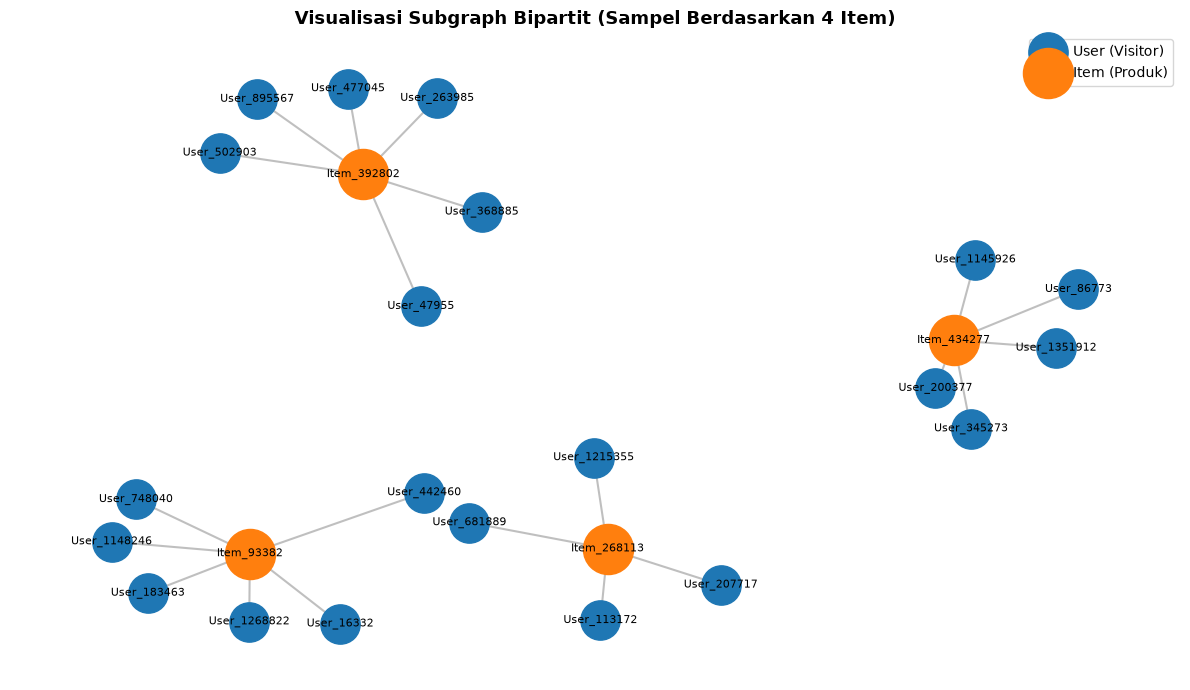

In [8]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix
import networkx as nx
import matplotlib.pyplot as plt

# 1. PEMBENTUKAN MATRIKS VSM SIMPUL USER (USER x ITEM)
if 'df_p1' not in locals():
    df_p1 = pd.read_csv(r"C:\Users\lovia\Documents\SEMESTER 7\Graf Sains Data\UTS\dataset\events_P1.csv")

event_weights = {'view': 1, 'addtocart': 2, 'transaction': 3}
weights = df_p1['event'].map(event_weights).fillna(1).values

user_cats = df_p1['visitorid'].astype('category')
item_cats = df_p1['itemid'].astype('category')

user_indices = user_cats.cat.codes
item_indices = item_cats.cat.codes

vsm_user_matrix = csr_matrix(
    (weights, (user_indices, item_indices)),
    shape=(len(user_cats.cat.categories), len(item_cats.cat.categories))
)

# 2. HITUNG & TAMPILKAN KARAKTERISTIK VSM SIMPUL USER
n_users, n_items = vsm_user_matrix.shape
non_zero = vsm_user_matrix.nnz
total_elements = n_users * n_items
sparsity = (1.0 - (non_zero / total_elements)) * 100

print("KARAKTERISTIK VSM SIMPUL USER")
print(f"1. Dimensi Ruang Vektor (Features/Items) : {n_items:,} dimensi")
print(f"2. Bentuk Matriks (Shape User x Item)   : {vsm_user_matrix.shape}")
print(f"3. Jumlah Non-Zero Elements (Interaksi) : {non_zero:,} sel terisi")
print(f"4. Total Seluruh Elemen Matriks         : {total_elements:,} sel")
print(f"5. Tingkat Kelangkaan (Sparsity)        : {sparsity:.5f} %")

# 3. SAMPLING BERDASARKAN 4 ITEM (DEGREE 3 - 6) & VISUALISASI GRAF
item_counts = df_p1['itemid'].value_counts()
sample_item_ids = item_counts[(item_counts >= 3) & (item_counts <= 6)].head(4).index
sub_df_item = df_p1[df_p1['itemid'].isin(sample_item_ids)].drop_duplicates(subset=['visitorid', 'itemid'])

# Buat graf bipartit
B = nx.Graph()
u_nodes = [f"User_{uid}" for uid in sub_df_item['visitorid'].unique()]
i_nodes = [f"Item_{iid}" for iid in sample_item_ids]

B.add_nodes_from(u_nodes, bipartite=0)
B.add_nodes_from(i_nodes, bipartite=1)

for _, r in sub_df_item.iterrows():
    B.add_edge(f"User_{r['visitorid']}", f"Item_{r['itemid']}")

pos = nx.spring_layout(B, k=0.45, seed=42)
plt.figure(figsize=(12, 7))

nx.draw_networkx_nodes(
    B, pos, 
    nodelist=u_nodes, 
    node_color='#1f77b4', 
    node_size=800, 
    label="User (Visitor)"
)

nx.draw_networkx_nodes(
    B, pos, 
    nodelist=i_nodes, 
    node_color='#ff7f0e', 
    node_size=1300, 
    label="Item (Produk)"
)

# Garis relasi & Label
nx.draw_networkx_edges(B, pos, edge_color='#B0B0B0', width=1.5, alpha=0.8)
nx.draw_networkx_labels(B, pos, font_size=8, font_color='black')

plt.title("Visualisasi Subgraph Bipartit (Sampel Berdasarkan 4 Item)", fontsize=13, fontweight='bold')
plt.legend(scatterpoints=1, loc='upper right', frameon=True)
plt.axis('off')
plt.tight_layout()
plt.show()


5. Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

KARAKTERISTIK VSM SIMPUL ITEM
1. Dimensi Ruang Vektor (Features/Users) : 74,982 dimensi
2. Bentuk Matriks (Shape Item x User)   : (49970, 74982)
3. Jumlah Non-Zero Elements (Interaksi) : 110,002 sel terisi
4. Total Seluruh Elemen Matriks         : 3,746,850,540 sel
5. Tingkat Kelangkaan (Sparsity)        : 99.99706 %


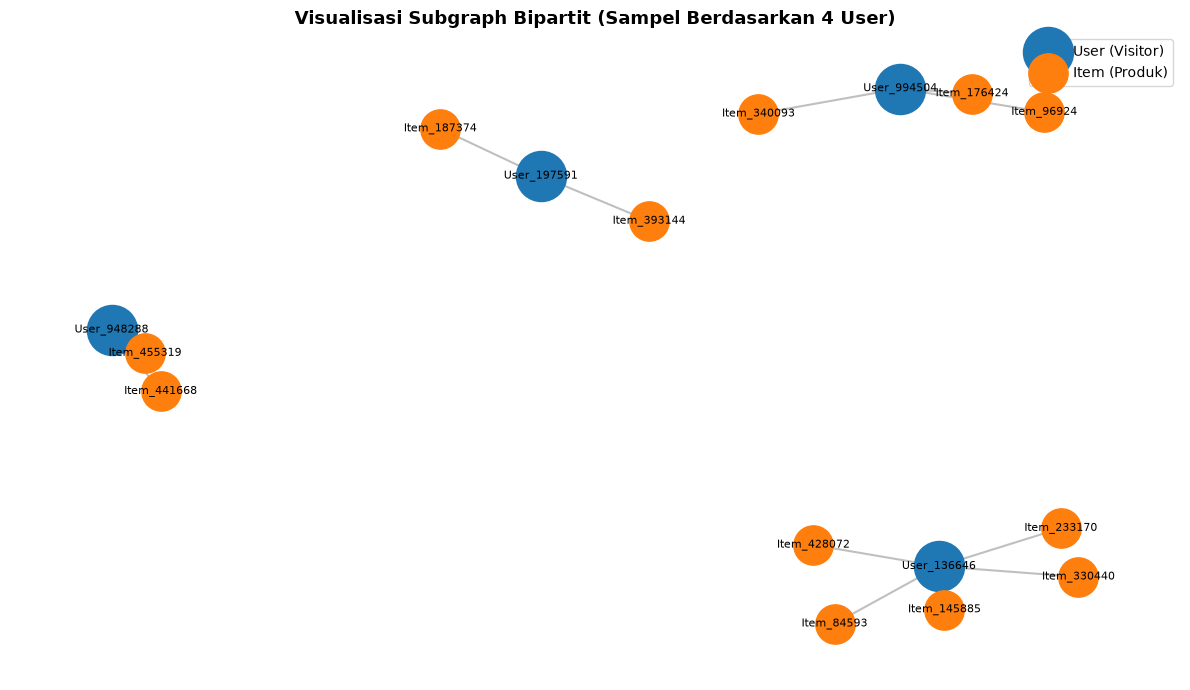

In [9]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix
import networkx as nx
import matplotlib.pyplot as plt

# 1. PEMBENTUKAN MATRIKS VSM SIMPUL ITEM (ITEM x USER)
if 'df_p1' not in locals():
    df_p1 = pd.read_csv(r"C:\Users\lovia\Documents\SEMESTER 7\Graf Sains Data\UTS\dataset\events_P1.csv")

event_weights = {'view': 1, 'addtocart': 2, 'transaction': 3}
weights = df_p1['event'].map(event_weights).fillna(1).values

user_cats = df_p1['visitorid'].astype('category')
item_cats = df_p1['itemid'].astype('category')

user_indices = user_cats.cat.codes
item_indices = item_cats.cat.codes

vsm_item_matrix = csr_matrix(
    (weights, (item_indices, user_indices)),
    shape=(len(item_cats.cat.categories), len(user_cats.cat.categories))
)

# 2. HITUNG & TAMPILKAN KARAKTERISTIK VSM SIMPUL ITEM
n_items, n_users = vsm_item_matrix.shape
non_zero = vsm_item_matrix.nnz
total_elements = n_items * n_users
sparsity = (1.0 - (non_zero / total_elements)) * 100

print("KARAKTERISTIK VSM SIMPUL ITEM")
print(f"1. Dimensi Ruang Vektor (Features/Users) : {n_users:,} dimensi")
print(f"2. Bentuk Matriks (Shape Item x User)   : {vsm_item_matrix.shape}")
print(f"3. Jumlah Non-Zero Elements (Interaksi) : {non_zero:,} sel terisi")
print(f"4. Total Seluruh Elemen Matriks         : {total_elements:,} sel")
print(f"5. Tingkat Kelangkaan (Sparsity)        : {sparsity:.5f} %")

# 3. SAMPLING BERDASARKAN 4 USER (DEGREE 3 - 6) & VISUALISASI GRAF
user_counts = df_p1['visitorid'].value_counts()
sample_user_ids = user_counts[(user_counts >= 3) & (user_counts <= 6)].head(4).index
sub_df_user = df_p1[df_p1['visitorid'].isin(sample_user_ids)].drop_duplicates(subset=['visitorid', 'itemid'])

# Buat graf bipartit
B = nx.Graph()
u_nodes = [f"User_{uid}" for uid in sample_user_ids]
i_nodes = [f"Item_{iid}" for iid in sub_df_user['itemid'].unique()]

B.add_nodes_from(u_nodes, bipartite=0)
B.add_nodes_from(i_nodes, bipartite=1)

for _, r in sub_df_user.iterrows():
    B.add_edge(f"User_{r['visitorid']}", f"Item_{r['itemid']}")

pos = nx.spring_layout(B, k=0.45, seed=42)
plt.figure(figsize=(12, 7))

nx.draw_networkx_nodes(
    B, pos, 
    nodelist=u_nodes, 
    node_color='#1f77b4', 
    node_size=1300, 
    label="User (Visitor)"
)

nx.draw_networkx_nodes(
    B, pos, 
    nodelist=i_nodes, 
    node_color='#ff7f0e', 
    node_size=800, 
    label="Item (Produk)"
)

# Garis relasi & Label
nx.draw_networkx_edges(B, pos, edge_color='#B0B0B0', width=1.5, alpha=0.8)
nx.draw_networkx_labels(B, pos, font_size=8, font_color='black')

plt.title("Visualisasi Subgraph Bipartit (Sampel Berdasarkan 4 User)", fontsize=13, fontweight='bold')
plt.legend(scatterpoints=1, loc='upper right', frameon=True)
plt.axis('off')
plt.tight_layout()
plt.show()

6. Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!

- Efisiensi
Simpul item memiliki ruang matriks yang lebih kecil dari simpul user, yakni 49,970, sehingga memangkas kebutuhan memori

- Efektivitas
Relasi antar item lebih efektif. Satu produk bisa berulang kali dilihat oleh banyak orang berbeda, hal ini membuat relasi antar item memiliki density yang lebih kuat. Pola ini sejalan dengan konsep Item-based Collaborative Filtering yang biasa dipakai di industri e-commerce.

7.

In [10]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix
from neo4j import GraphDatabase

if 'df_p1' not in locals():
    df_p1 = pd.read_csv(r"C:\Users\lovia\Documents\SEMESTER 7\Graf Sains Data\UTS\dataset\events_P1.csv")

event_weights = {'view': 1, 'addtocart': 2, 'transaction': 3}
weights = df_p1['event'].map(event_weights).fillna(1).values

user_cats = df_p1['visitorid'].astype('category')
item_cats = df_p1['itemid'].astype('category')

vsm_item_matrix = csr_matrix(
    (weights, (item_cats.cat.codes, user_cats.cat.codes)),
    shape=(len(item_cats.cat.categories), len(user_cats.cat.categories))
)

# 1. Tentukan item acuan
target_item_id = 309778
target_idx = list(item_cats.cat.categories).index(target_item_id)
target_vec = vsm_item_matrix[target_idx]

# 2. Hitung Cosine Similarity terhadap seluruh item
dot_products = vsm_item_matrix.dot(target_vec.T).toarray().flatten()
norms = np.sqrt(vsm_item_matrix.multiply(vsm_item_matrix).sum(axis=1)).A.flatten()
target_norm = np.linalg.norm(target_vec.toarray())
norms[norms == 0] = 1e-9

sim_scores = dot_products / (norms * target_norm)
top_indices = np.argsort(sim_scores)[::-1]
items_cat = item_cats.cat.categories

print(f"HASIL COSINE SIMILARITY DENGAN PYTHON (Item Acuan: {target_item_id})")
rank = 1
for idx in top_indices:
    item_id = items_cat[idx]
    if item_id != target_item_id and sim_scores[idx] > 0:
        print(f"Rank {rank}: Item {item_id:<7} | Cosine Similarity: {sim_scores[idx]:.4f}")
        rank += 1
        if rank > 5:
            break


HASIL COSINE SIMILARITY DENGAN PYTHON (Item Acuan: 309778)
Rank 1: Item 257040  | Cosine Similarity: 0.2063
Rank 2: Item 190806  | Cosine Similarity: 0.1959
Rank 3: Item 236578  | Cosine Similarity: 0.1959
Rank 4: Item 115326  | Cosine Similarity: 0.1959
Rank 5: Item 53207   | Cosine Similarity: 0.1959


In [11]:
import pandas as pd
from neo4j import GraphDatabase

cypher_top5 = """
MATCH (target:Item {itemId: 309778})<-[r1]-(v:Visitor)-[r2]->(other:Item)
WHERE target <> other
WITH target, other, count(DISTINCT v) AS intersection_count
MATCH (target)<-[]-(v1:Visitor)
WITH target, other, intersection_count, count(DISTINCT v1) AS target_count
MATCH (other)<-[]-(v2:Visitor)
WITH target, other, target_count, count(DISTINCT v2) AS other_count, intersection_count
WITH target.itemId AS item_acuan,
     other.itemId AS similar_item,
     round(toFloat(intersection_count) / (target_count + other_count - intersection_count), 4) AS similarity_score
RETURN item_acuan, similar_item, similarity_score
ORDER BY similarity_score DESC
LIMIT 5
"""

with GraphDatabase.driver(args.bolt, auth=(args.user, args.password)) as driver:
    with driver.session(database="neo4j") as session:
        result = session.run(cypher_top5)
        df_top5 = pd.DataFrame([r.data() for r in result])

print("5 Records dengan Similarity Tertinggi untuk Item 309778")
df_top5


5 Records dengan Similarity Tertinggi untuk Item 309778


,item_acuan,similar_item,similarity_score
0,309778,257040,0.1278
1,309778,115889,0.0537
2,309778,360487,0.0510
3,309778,135900,0.0423
4,309778,279052,0.0360


8. Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity!

In [12]:
import pandas as pd
from neo4j import GraphDatabase

cypher_before = """
MATCH (target:Item {itemId: 309778})<-[r1]-(v:Visitor)-[r2]->(other:Item)
WHERE other.itemId IN [257040, 115889, 360487, 135900, 279052]
RETURN target.itemId AS item_acuan, 
       type(r1) AS relasi_target, 
       v.visitorId AS visitor_perantara, 
       type(r2) AS relasi_other, 
       other.itemId AS item_tujuan
LIMIT 5
"""

with GraphDatabase.driver(args.bolt, auth=(args.user, args.password)) as driver:
    with driver.session(database="neo4j") as session:
        result_before = session.run(cypher_before)
        df_before = pd.DataFrame([r.data() for r in result_before])

print("HASIL QUERY CYPHER KONDISI SEBELUM PERHITUNGAN SIMILARITY")
df_before


HASIL QUERY CYPHER KONDISI SEBELUM PERHITUNGAN SIMILARITY


,item_acuan,relasi_target,visitor_perantara,relasi_other,item_tujuan
0,309778,VIEWED,1065255,VIEWED,257040
1,309778,VIEWED,1065255,VIEWED,279052
2,309778,VIEWED,1065255,VIEWED,279052
3,309778,VIEWED,1065255,VIEWED,279052
4,309778,VIEWED,1065255,VIEWED,257040


In [13]:
cypher_after = """
MATCH (target:Item {itemId: 309778})-[s:SIMILAR_TO]-(other:Item)
RETURN target.itemId AS item_acuan, 
       type(s) AS jenis_relasi, 
       other.itemId AS item_mirip, 
       s.score AS similarity_score
ORDER BY similarity_score DESC
"""

with GraphDatabase.driver(args.bolt, auth=(args.user, args.password)) as driver:
    with driver.session(database="neo4j") as session:
        result_after = session.run(cypher_after)
        df_after = pd.DataFrame([r.data() for r in result_after])

print("HASIL QUERY CYPHER KONDISI SESUDAH PERHITUNGAN SIMILARITY")
df_after


HASIL QUERY CYPHER KONDISI SESUDAH PERHITUNGAN SIMILARITY


,item_acuan,jenis_relasi,item_mirip,similarity_score
0,309778,SIMILAR_TO,257040,0.1278
1,309778,SIMILAR_TO,115889,0.0537
2,309778,SIMILAR_TO,360487,0.0510
3,309778,SIMILAR_TO,135900,0.0423
4,309778,SIMILAR_TO,279052,0.0360


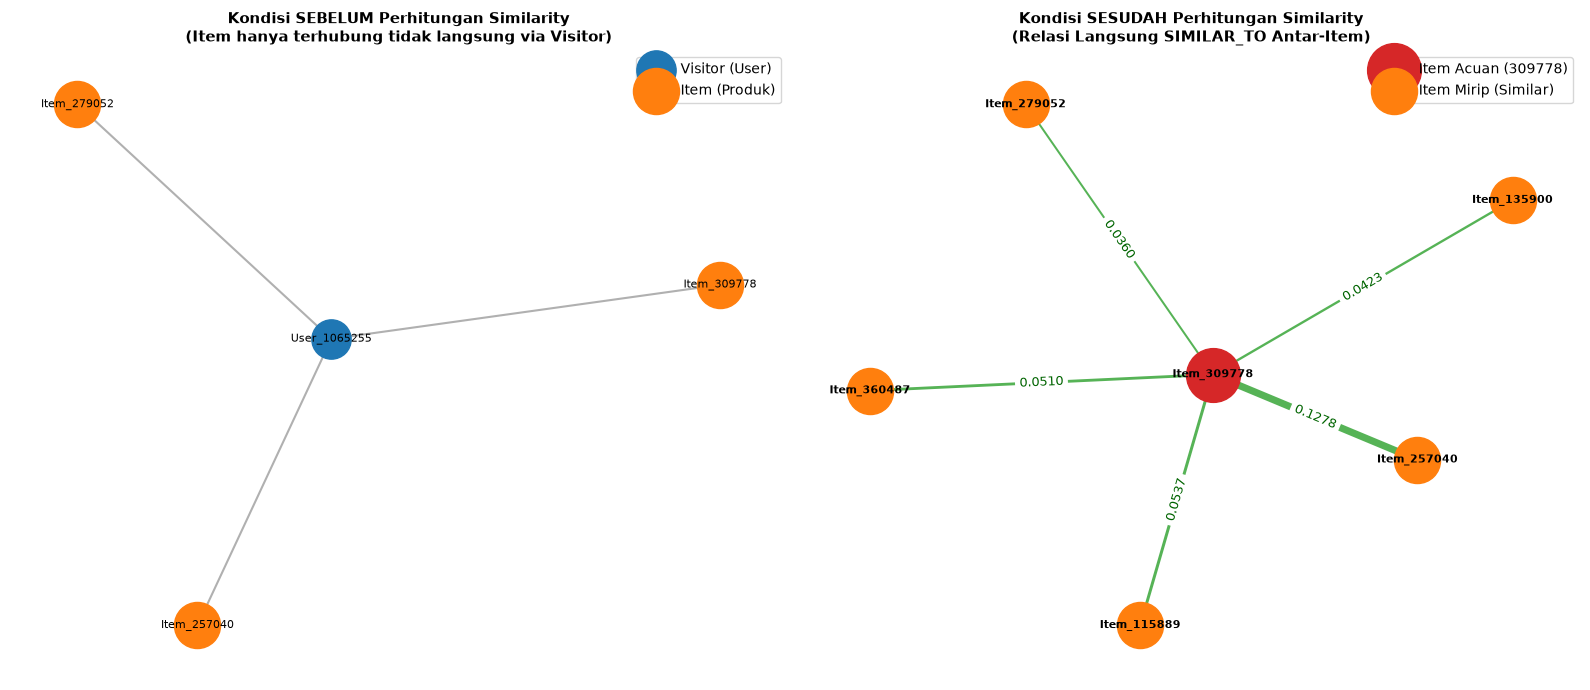

In [14]:
import matplotlib.pyplot as plt
import networkx as nx

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# 1. VISUALISASI GRAF SEBELUM (Bipartit via Visitor)
G_b = nx.Graph()
for _, row in df_before.iterrows():
    t_node = f"Item_{row['item_acuan']}"
    u_node = f"User_{row['visitor_perantara']}"
    o_node = f"Item_{row['item_tujuan']}"
    G_b.add_edge(u_node, t_node)
    G_b.add_edge(u_node, o_node)

users_b = [n for n in G_b.nodes() if n.startswith("User_")]
items_b = [n for n in G_b.nodes() if n.startswith("Item_")]

pos_b = nx.spring_layout(G_b, seed=42, k=0.5)

nx.draw_networkx_nodes(G_b, pos_b, nodelist=users_b, node_color='#1f77b4', node_size=800, ax=axes[0], label="Visitor (User)")
nx.draw_networkx_nodes(G_b, pos_b, nodelist=items_b, node_color='#ff7f0e', node_size=1100, ax=axes[0], label="Item (Produk)")
nx.draw_networkx_edges(G_b, pos_b, edge_color='#B0B0B0', width=1.5, ax=axes[0])
nx.draw_networkx_labels(G_b, pos_b, font_size=8, font_color='black', ax=axes[0])

axes[0].set_title("Kondisi SEBELUM Perhitungan Similarity\n(Item hanya terhubung tidak langsung via Visitor)", fontsize=11, fontweight='bold')
axes[0].legend(loc='upper right')
axes[0].axis('off')

# 2. VISUALISASI GRAF SESUDAH (Relasi Langsung SIMILAR_TO)
G_a = nx.Graph()
t_main = "Item_309778"
sim_labels = {}

for _, row in df_after.iterrows():
    o_node = f"Item_{row['item_mirip']}"
    score = row['similarity_score']
    G_a.add_edge(t_main, o_node, weight=score)
    sim_labels[(t_main, o_node)] = f"{score:.4f}"

pos_a = nx.spring_layout(G_a, seed=42, k=0.6)

nx.draw_networkx_nodes(G_a, pos_a, nodelist=[t_main], node_color='#d62728', node_size=1500, ax=axes[1], label="Item Acuan (309778)")
nx.draw_networkx_nodes(G_a, pos_a, nodelist=[n for n in G_a.nodes() if n != t_main], node_color='#ff7f0e', node_size=1100, ax=axes[1], label="Item Mirip (Similar)")

widths = [d['weight'] * 40 for _, _, d in G_a.edges(data=True)]
nx.draw_networkx_edges(G_a, pos_a, edge_color='#2ca02c', width=widths, alpha=0.8, ax=axes[1])
nx.draw_networkx_labels(G_a, pos_a, font_size=8, font_color='black', font_weight='bold', ax=axes[1])
nx.draw_networkx_edge_labels(G_a, pos_a, edge_labels=sim_labels, font_color='darkgreen', font_size=9, ax=axes[1])

axes[1].set_title("Kondisi SESUDAH Perhitungan Similarity\n(Relasi Langsung SIMILAR_TO Antar-Item)", fontsize=11, fontweight='bold')
axes[1].legend(loc='upper right')
axes[1].axis('off')

plt.tight_layout()
plt.show()


## 2.2 Analytics 

1. Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu
- (a) tuliskan skrip Python dalam merekomendasikan KNN-nya!
- (b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!

In [15]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix

if 'df_p1' not in locals():
    df_p1 = pd.read_csv(r"C:\Users\lovia\Documents\SEMESTER 7\Graf Sains Data\UTS\dataset\events_P1.csv")
if 'df_p2' not in locals():
    df_p2 = pd.read_csv(r"C:\Users\lovia\Documents\SEMESTER 7\Graf Sains Data\UTS\dataset\events_P2.csv")

# Ambil user yang berinteraksi di P1 dan juga aktif di P2
p1_users = set(df_p1['visitorid'].unique())
p2_users = set(df_p2['visitorid'].unique())
common_users = sorted(list(p1_users.intersection(p2_users)))

# Filter user aktif di P1 (3 s.d. 8 item) yang juga aktif di P2
user_item_counts = df_p1.groupby('visitorid')['itemid'].nunique()
eligible_users = np.sort([u for u in common_users if 3 <= user_item_counts[u] <= 8])

np.random.seed(197)  
target_user = int(np.random.choice(eligible_users))
items_seen = set(df_p1[df_p1['visitorid'] == target_user]['itemid'].unique())

# 2. PEMBENTUKAN MATRIKS VSM USER (USER x ITEM)
event_weights = {'view': 1, 'addtocart': 2, 'transaction': 3}
weights = df_p1['event'].map(event_weights).fillna(1).values

user_cats = df_p1['visitorid'].astype('category')
item_cats = df_p1['itemid'].astype('category')

vsm_user_matrix = csr_matrix(
    (weights, (user_cats.cat.codes, item_cats.cat.codes)),
    shape=(len(user_cats.cat.categories), len(item_cats.cat.categories))
)

user_list = list(user_cats.cat.categories)
items_list = list(item_cats.cat.categories)

# 3. CARI 5 TETANGGA TERDEKAT (KNN, k = 5) BERBASIS COSINE SIMILARITY
target_idx = user_list.index(target_user)
target_vec = vsm_user_matrix[target_idx]

dot_products = vsm_user_matrix.dot(target_vec.T).toarray().flatten()
norms = np.sqrt(vsm_user_matrix.multiply(vsm_user_matrix).sum(axis=1)).A.flatten()
target_norm = np.linalg.norm(target_vec.toarray())
norms[norms == 0] = 1e-9

sim_scores = dot_products / (norms * target_norm)
top_user_indices = np.argsort(sim_scores)[::-1]

knn_users = []
for idx in top_user_indices:
    uid = user_list[idx]
    if uid != target_user and sim_scores[idx] > 0:
        knn_users.append((uid, sim_scores[idx], idx))
        if len(knn_users) == 5:
            break

print(" 5 TETANGGA TERDEKAT (KNN: k = 5)")
for rank, (uid, sim, _) in enumerate(knn_users, 1):
    print(f"Tetangga {rank}: User ID {uid:<8} | Cosine Similarity: {sim:.4f}")

rec_scores = {}
for uid, sim, u_idx in knn_users:
    u_vector = vsm_user_matrix[u_idx].tocoo()
    for col_idx, w in zip(u_vector.col, u_vector.data):
        item_id = items_list[col_idx]
        if item_id not in items_seen:
            rec_scores[item_id] = rec_scores.get(item_id, 0.0) + (sim * w)

top_3_items = sorted(rec_scores.items(), key=lambda x: x[1], reverse=True)[:3]

print(f"       3 ITEM YANG DIIKLANKAN UNTUK USER {target_user} (k = 5)")

df_rekomendasi = pd.DataFrame([
    {
        'Peringkat': f"Top-{i+1}",
        'Item ID': item_id,
        'Skor Rekomendasi': round(score, 4),
        'Status': "Belum pernah dilihat (Relevan)"
    }
    for i, (item_id, score) in enumerate(top_3_items)
])

print(df_rekomendasi.to_string(index=False))


 5 TETANGGA TERDEKAT (KNN: k = 5)
Tetangga 1: User ID 1006883  | Cosine Similarity: 0.5774
Tetangga 2: User ID 577287   | Cosine Similarity: 0.5774
Tetangga 3: User ID 863565   | Cosine Similarity: 0.4082
Tetangga 4: User ID 444644   | Cosine Similarity: 0.2357
Tetangga 5: User ID 428399   | Cosine Similarity: 0.1543
       3 ITEM YANG DIIKLANKAN UNTUK USER 243844 (k = 5)
Peringkat  Item ID  Skor Rekomendasi                         Status
    Top-1   276704            0.4714 Belum pernah dilihat (Relevan)
    Top-2    10034            0.4629 Belum pernah dilihat (Relevan)
    Top-3    98109            0.4082 Belum pernah dilihat (Relevan)


2. Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:
- (a) Hit@5
- (b) NDCG@5

In [18]:
import pandas as pd
import numpy as np

if 'df_p2' not in locals():
    df_p2 = pd.read_csv(r"C:\Users\lovia\Documents\SEMESTER 7\Graf Sains Data\UTS\dataset\events_P2.csv")

top5_recs = [item_id for item_id, _ in sorted(rec_scores.items(), key=lambda x: x[1], reverse=True)[:5]]
actual_items_p2 = set(df_p2[df_p2['visitorid'] == target_user]['itemid'].unique())

print(f"EVALUASI ANALITIK: (User {target_user})")
print(f"Top 5 Rekomendasi Model : {top5_recs}")
print(f"Ground Truth Aktual (P2): {sorted(list(actual_items_p2))}")

# (a) HITUNG HIT@5
hits = [1 if item in actual_items_p2 else 0 for item in top5_recs]
hit_at_5 = 1 if sum(hits) > 0 else 0

print(f"Hits per peringkat (1-5): {hits}")

# (b) HITUNG NDCG@5
dcg_5 = sum((2**rel - 1) / np.log2(idx + 2) for idx, rel in enumerate(hits))

num_relevant = min(len(actual_items_p2), 5)
idcg_5 = sum(1.0 / np.log2(idx + 2) for idx in range(num_relevant)) if num_relevant > 0 else 0.0

ndcg_at_5 = (dcg_5 / idcg_5) if idcg_5 > 0 else 0.0

print("\nHASIL PERHITUNGAN:")
print(f"(a) Hit@5  : {hit_at_5}")
print(f"(b) NDCG@5 : {ndcg_at_5:.4f}")



EVALUASI ANALITIK: (User 243844)
Top 5 Rekomendasi Model : [276704, 10034, 98109, 292240, 96985]
Ground Truth Aktual (P2): [np.int64(44433), np.int64(276704), np.int64(366415), np.int64(417187)]
Hits per peringkat (1-5): [1, 0, 0, 0, 0]

HASIL PERHITUNGAN:
(a) Hit@5  : 1
(b) NDCG@5 : 0.3904
